# Gaussian toy model

The following notebook contains a series of tests on the Lipschitz constrained model using a gaussian function as the target function. The structure is as follows: First, we generate a gaussian function with a given standard deviation $\sigma$ and compute its Lipschitz constant. Then, we evaluate the optimal fit of an L-Lipschitz function to the gaussian function for a range of L values. This sets us up for comparison so we can verify that the Lipschitz constrained model is able to learn the optimal fit for a given L.

When these prerequisites are done we can examine when the model breaks down.

In [1]:
import os
import sys
import random
import numpy as np
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import tqdm

import monotonicnetworks as lmn

import matplotlib.pyplot as plt


In [2]:

# "Homemade" modules
%load_ext autoreload
%autoreload 2
from Toy_utils import sine_function_train_data, gaussian_function_data, BasicDataset, calculate_lipschitz_constant, gaussian_lipschitz_constant, FWHM_calculation
from lipschitz_floor import lipschitz_floor, lipschitz_floor_scan
from models import LipschitzModel, UnconstrainedModel
from train_eval import train, predict
#from models import UnconstrainedModel, LipschitzModel
#from train_eval import train, evaluate, predict


# The Gaussian function
The Gaussian function is defined as:
$$
f(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\left(-\frac{x^2}{2\sigma^2}\right)
$$
We can set $\mu=0$ for simplicity as we are only interested in the shape and the gradients of the function. The Lipschitz constant of the Gaussian function is inversely proportional to the standard deviation $\sigma$ of the Gaussian. The sharper the Gaussian, the higher the Lipschitz constant.

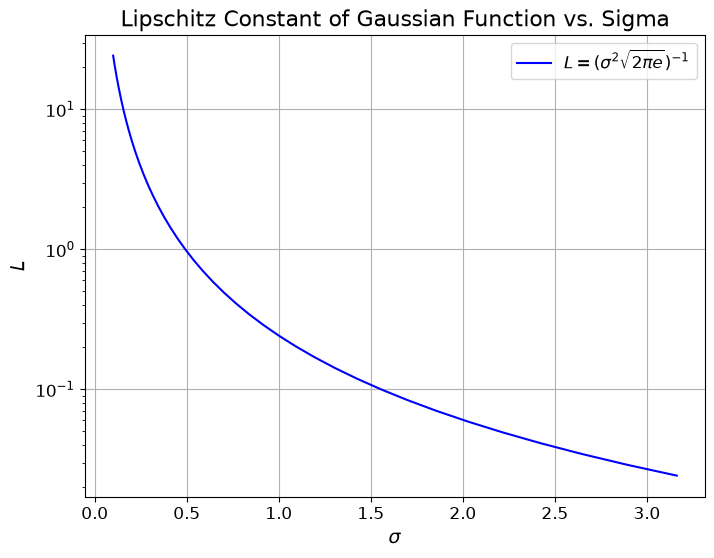

In [3]:
# The Lipschitz constant as a function of the standard deviation
sigma_values = np.logspace(-1, 0.5, 40)  # Example range of sigma values
#sigma_values = np.linspace(0.1, 2.0, 20)  # Example range of sigma values
L_gaussian = gaussian_lipschitz_constant(sigma_values)

plt.figure(figsize=(8, 6))
plt.plot(sigma_values, L_gaussian, label='$L=(\\sigma^2 \\sqrt{2\\pi e})^{-1}$', color='blue')
plt.title('Lipschitz Constant of Gaussian Function vs. Sigma', fontsize=16)
plt.yscale('log')
plt.xlabel('$\\sigma$', fontsize=14)
plt.ylabel('$L$', fontsize=14)
plt.grid(True)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(fontsize=12)
plt.show()


In other words, the sharper the gaussian, the higher the Lipschitz constant.

# Floor function
The first part is to establish the theoretical baseline for the best possible fit. Through a quadratic programming approach we can compute the best possible L-Lipschitz fit to a gaussian function. Doing this for a range of L values lets us examine how the errors propagate as we move away from the true Lipschitz constant, as well as how the errors change with sharper gaussians

In [13]:
# The cost of the different Lipschitz constants
# Compute the best possible Lipschitz fit for the different L, and compare the errors and the FWHM of the different fits. 
from lipschitz_floor import lipschitz_floor_scan
# Making a gaussian
N = 2000
MU = 0
SIGMA = 0.1
NOISE_MAGNITUDE = 0.1

x_gaussian_train, y_gaussian_train, x_gaussian_linspace, y_gaussian_linspace = gaussian_function_data(N=N, mu=MU, sigma=SIGMA, noise_magnitude=NOISE_MAGNITUDE)

# Scan of L values
L_true = gaussian_lipschitz_constant(SIGMA)
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_true:.4f}")
L_scan = np.logspace(np.log10(0.01 * L_true), np.log10(2 * L_true), 40)

# Compute MSE
floor_dict, MSE_dict = {}, {}
for L in L_scan:
    print(f"Computing Lipschitz floor for L={L:.4f}")
    floor_dict[str(L)], MSE_dict[str(L)] = lipschitz_floor(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), L)

#MSE_floors = lipschitz_floor_scan(x_gaussian_linspace.numpy(), y_gaussian_linspace.numpy(), L_scan)


Lipschitz constant of the Gaussian function with sigma=0.1: 24.1971
Computing Lipschitz floor for L=0.2420
Computing Lipschitz floor for L=0.2772
Computing Lipschitz floor for L=0.3175
Computing Lipschitz floor for L=0.3637
Computing Lipschitz floor for L=0.4166
Computing Lipschitz floor for L=0.4773
Computing Lipschitz floor for L=0.5467
Computing Lipschitz floor for L=0.6263
Computing Lipschitz floor for L=0.7174
Computing Lipschitz floor for L=0.8218
Computing Lipschitz floor for L=0.9414
Computing Lipschitz floor for L=1.0784
Computing Lipschitz floor for L=1.2353
Computing Lipschitz floor for L=1.4151
Computing Lipschitz floor for L=1.6210
Computing Lipschitz floor for L=1.8568
Computing Lipschitz floor for L=2.1270
Computing Lipschitz floor for L=2.4366
Computing Lipschitz floor for L=2.7911
Computing Lipschitz floor for L=3.1973
Computing Lipschitz floor for L=3.6625
Computing Lipschitz floor for L=4.1955
Computing Lipschitz floor for L=4.8060
Computing Lipschitz floor for L=5.5

In [22]:
MSE_dict.values().array()

AttributeError: 'dict_values' object has no attribute 'array'

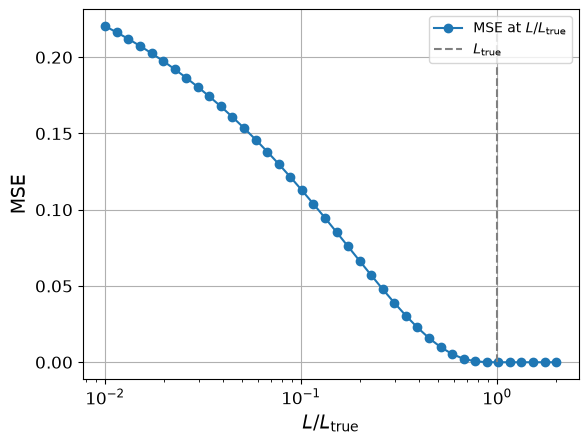

In [34]:
MSE_floors = list(MSE_dict.values())
plt.plot(L_scan/L_true, MSE_floors, '-o', label='MSE at $L/L_{\\text{true}}$')
plt.vlines(1.0, ymin=min(MSE_floors), ymax=max(MSE_floors), colors='grey', linestyles='dashed', label='$L_{\\text{true}}$')
plt.xscale('log')
#plt.yscale('log')
plt.xlabel(r'$L / L_{\text{true}}$', fontsize=14)
plt.ylabel('MSE', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
#plt.title('MSE of Best L-Lipschitz Fit vs. Lipschitz Constant')
plt.legend()
#plt.savefig('Plots/gaussian_lipschitz_floor.pdf')
plt.show()

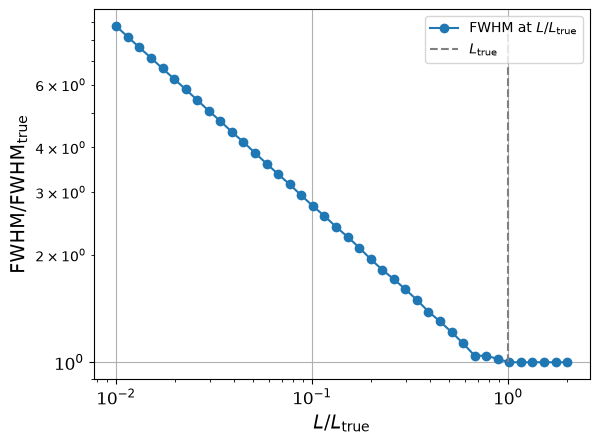

In [44]:
# Plotting the FWHM of the different fits
FWHM_values = [FWHM_calculation(x_gaussian_linspace, floor_dict[str(L)]) for L in L_scan]
FWHM_true = FWHM_calculation(x_gaussian_linspace.detach().numpy(), y_gaussian_linspace.detach().numpy())
plt.plot(L_scan/L_true, FWHM_values/FWHM_true, '-o', label='FWHM at $L/L_{\\text{true}}$')
plt.vlines(1.0, ymin=min(FWHM_values/FWHM_true), ymax=max(FWHM_values/FWHM_true), colors='grey', linestyles='dashed', label='$L_{\\text{true}}$')
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$L / L_{\text{true}}$', fontsize=14)
plt.ylabel(r'$\text{FWHM}/\text{FWHM}_{\text{true}}$', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.grid()
#plt.title('FWHM of Best L-Lipschitz Fit vs. Lipschitz Constant')
plt.legend()
#plt.savefig('Plots/gaussian_lipschitz_floor_FWHM.pdf')
plt.show()

In [4]:
# Floor error as a function of sigma and L / L_true
# For a fair comparison between Gaussians of different width, every (sigma, L) gets its own grid:
#  - the domain contains both the peak (6 sigma) and the full tent of the floor (half-width w_L = sqrt(area / L)),
#  - the grid has the same number of points per sigma for every Gaussian.
# Two errors are stored:
#  - the integrated squared error ISE = int (g - f)^2 dx. It has units, and for unit-area Gaussians it scales
#    exactly as 1 / sigma (narrow peaks are taller, so the same relative mistake costs more),
#  - the relative error ISE / int f^2 dx. It is dimensionless and should only depend on L / L_true.


def floor_errors(sigma, L, points_per_sigma=40, area=1.0):
    """Integrated squared error and relative error of the best L-Lipschitz fit to a Gaussian of width sigma."""
    w_L = np.sqrt(area / L)
    half_width = max(6 * sigma, 1.5 * w_L)
    n = int(2 * half_width / sigma * points_per_sigma) + 1
    x = np.linspace(-half_width, half_width, n)
    f = area * np.exp(-x**2 / (2 * sigma**2)) / (sigma * np.sqrt(2 * np.pi))
    g, _ = lipschitz_floor(x, f, L)
    ise = np.trapezoid((g - f) ** 2, x)
    return ise, ise / np.trapezoid(f ** 2, x)


sigma_values = np.logspace(-1, 0.5, 10)
r_values = np.logspace(-2, np.log10(2), 30)  # L / L_true, the same grid for every sigma
ISE_matrix = np.zeros((len(sigma_values), len(r_values)))
relative_matrix = np.zeros_like(ISE_matrix)
for i, sigma in enumerate(sigma_values):
    L_true_i = gaussian_lipschitz_constant(sigma)  # local name, so the global L_true is not overwritten
    for j, r in enumerate(r_values):
        ISE_matrix[i, j], relative_matrix[i, j] = floor_errors(sigma, r * L_true_i)
    print(f"sigma = {sigma:.2f} done")

sigma = 0.10 done
sigma = 0.15 done
sigma = 0.22 done
sigma = 0.32 done
sigma = 0.46 done
sigma = 0.68 done
sigma = 1.00 done
sigma = 1.47 done
sigma = 2.15 done
sigma = 3.16 done


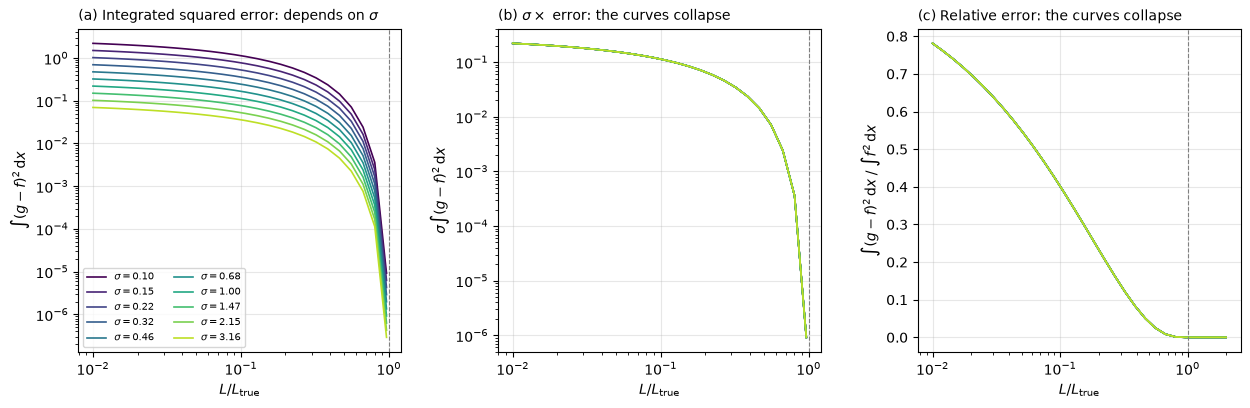

Largest relative spread of the relative error between sigma values: 1.9e-13


In [5]:
# The same errors, step by step: raw, with the trivial 1/sigma scaling removed, and relative
colors = plt.cm.viridis(np.linspace(0, 0.9, len(sigma_values)))
positive = lambda a: np.where(a > 0, a, np.nan)  # zeros (L >= L_true) cannot be drawn on a log axis

fig, axs = plt.subplots(1, 3, figsize=(15, 4.2), gridspec_kw=dict(wspace=0.3))
for i, (sigma, c) in enumerate(zip(sigma_values, colors)):
    axs[0].plot(r_values, positive(ISE_matrix[i]), color=c, lw=1.2, label=rf"$\sigma = {sigma:.2f}$")
    axs[1].plot(r_values, positive(sigma * ISE_matrix[i]), color=c, lw=1.2)
    axs[2].plot(r_values, relative_matrix[i], color=c, lw=1.2)
axs[0].set_title(r"(a) Integrated squared error: depends on $\sigma$", loc="left", fontsize=10)
axs[1].set_title(r"(b) $\sigma \times$ error: the curves collapse", loc="left", fontsize=10)
axs[2].set_title(r"(c) Relative error: the curves collapse", loc="left", fontsize=10)
axs[0].set_ylabel(r"$\int (g - f)^2\,\mathrm{d}x$")
axs[1].set_ylabel(r"$\sigma \int (g - f)^2\,\mathrm{d}x$")
axs[2].set_ylabel(r"$\int (g - f)^2\,\mathrm{d}x \;/\; \int f^2\,\mathrm{d}x$")
for ax in axs:
    ax.set_xscale("log")
    ax.set_xlabel(r"$L / L_\mathrm{true}$")
    ax.axvline(1, color="grey", lw=0.8, ls="--")
    ax.grid(True, alpha=0.3)
axs[0].set_yscale("log"); axs[1].set_yscale("log")
axs[0].legend(fontsize=7, ncol=2)
plt.show()

# How well do the curves collapse? Largest spread between the sigma values, relative to the mean
spread = (relative_matrix.max(0) - relative_matrix.min(0)) / np.where(relative_matrix.mean(0) > 0, relative_matrix.mean(0), np.nan)
print(f"Largest relative spread of the relative error between sigma values: {np.nanmax(spread):.1e}")

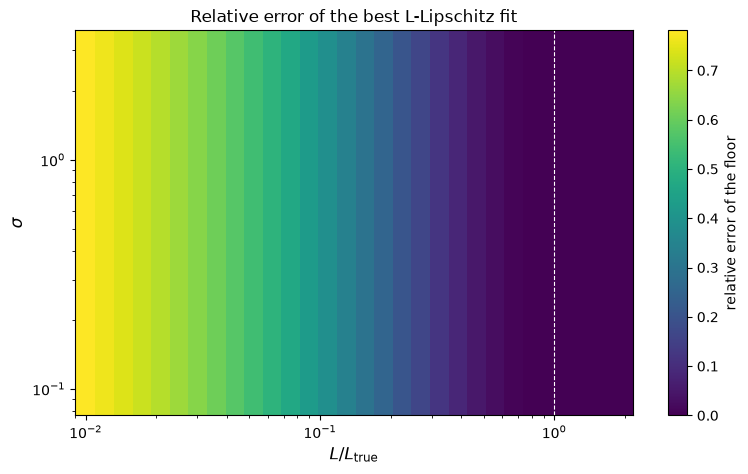

In [6]:
# Heatmap of the relative error over sigma and L / L_true. If only L / L_true matters, every row is the same
# (vertical stripes). pcolormesh with the real grid values keeps the logarithmic axes correct.
fig, ax = plt.subplots(figsize=(9, 5))
mesh = ax.pcolormesh(r_values, sigma_values, relative_matrix, shading="nearest", cmap="viridis")
fig.colorbar(mesh, ax=ax, label="relative error of the floor")
ax.axvline(1, color="white", lw=0.8, ls="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$L / L_\mathrm{true}$", fontsize=12)
ax.set_ylabel(r"$\sigma$", fontsize=12)
ax.set_title("Relative error of the best L-Lipschitz fit", fontsize=12)
# fig.savefig('Plots/gaussian_lipschitz_floor_heatmap.pdf', bbox_inches="tight")
plt.show()

In [7]:
# Optimal Floor fits for selected L-Lipschitz constants

# Making the narrow gaussian
N = 2000
MU = 0
SIGMA = 0.1
NOISE_MAGNITUDE = 0.1
_, _, x_linspace, y_linspace = gaussian_function_data(N=N, mu=MU, sigma=SIGMA, noise_magnitude=NOISE_MAGNITUDE)
L_true = gaussian_lipschitz_constant(SIGMA)
x_np = x_linspace.numpy().ravel()  # flat arrays: with shape (N, 1), differences like floor - y would broadcast to N x N
y_np = y_linspace.numpy().ravel()

# Selected L values for the floor fits
L_show = [L for L in [1, 3, 10, 20] if L < L_true]  # for L >= L_true the floor is the truth itself
floors = {L: lipschitz_floor(x_np, y_np, L)[0] for L in L_show}

In [8]:
print(floors[1])

[6.76643327e-14 6.76643327e-14 6.76643327e-14 ... 3.30271084e-14
 3.30271084e-14 3.30271084e-14]


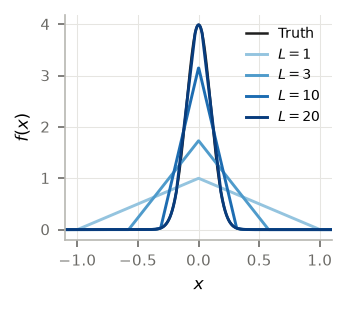

In [9]:

# Zoom to where the floors differ visibly from the truth (but stay inside the fitted range)
peak_true = y_np.max()
differs = np.any([np.abs(g - y_np) > 0.01 * peak_true for g in floors.values()], axis=0)
half_width = 1.15 * np.abs(x_np[differs] - MU).max() if differs.any() else 4 * SIGMA
x_lo, x_hi = max(x_np.min(), MU - half_width), min(x_np.max(), MU + half_width)


# --- Figures for the report
C_TRUE, C_FLOOR, C_NET, C_MUTED = "#1f1f1f", "#2a78d6", "#eb6834", "#6b6a66"
shades = plt.cm.Blues(np.linspace(0.4, 0.95, len(L_show)))  # one hue, light -> dark = small -> large L

PANEL_SIZE = (2.3, 1.95)  # inches, close to the final size of a 0.32\textwidth subfigure, so the fonts stay readable
REPORT_STYLE = {
    "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 6.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b8b7b2",
    "xtick.color": C_MUTED, "ytick.color": C_MUTED,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.5, "axes.axisbelow": True,
    "legend.frameon": False, "legend.handlelength": 1.6, "figure.dpi": 150, "savefig.bbox": "tight",
}

with plt.rc_context(REPORT_STYLE):
    # (a) What the floor looks like for different L
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    ax.plot(x_np, y_np, color=C_TRUE, lw=1.2, label="Truth")
    for L, c in zip(L_show, shades):
        ax.plot(x_np, floors[L], color=c, lw=1.4, label=rf"$L = {L:g}$")
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$")
    ax.legend(loc="upper right")
    fig.savefig("Plots/gaussian_cost_floor_fits.pdf")
    plt.show()

# Trained networks against the floor
The same Gaussian ($\sigma = 0.1$) and the same Lipschitz constants as the floor fits above, now learned by Lipschitz networks (width 64, depth 5, GroupSort with 8 groups, full-batch Adam, 3 seeds each), together with an unconstrained network of the same size as a reference. The networks are trained on the clean target, so they can be compared directly with the floor.

The figures use the same format as the floor fits, but in orange (implementation) instead of blue (theory). If the networks perform as expected, they reproduce the floor and use their full slope budget: the slope sits at exactly $\pm L$ on the sides of the tent. Runtime about 10 minutes.

In [59]:
# Train Lipschitz networks on the same Gaussian (sigma = 0.1) for the same L values as the floor fits above
from Toy_utils import train_full_batch

SEEDS_NET = [0, 1, 2]
HIDDEN_DIM_NET, N_GROUPS_NET, DEPTH_NET = 64, 8, 5

x_tensor = torch.tensor(x_np, dtype=torch.float32).unsqueeze(-1)
y_tensor = torch.tensor(y_np, dtype=torch.float32).unsqueeze(-1)  # clean target, so we can compare with the floor

net_fits, net_slopes = {}, {}  # net_fits[L], net_slopes[L]: arrays of shape (number of seeds, number of points)
for L in L_show:
    fits, slopes = [], []
    for seed in SEEDS_NET:
        torch.manual_seed(seed)
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM_NET, output_dim=1, n_groups=N_GROUPS_NET,
                               depth=DEPTH_NET, lipschitz_bound=L)
        train_full_batch(model, x_tensor, y_tensor)

        # Output and slope df/dx of the trained network at every grid point (slope via autograd)
        x_req = x_tensor.clone().requires_grad_(True)
        out = model(x_req)
        slope, = torch.autograd.grad(out.sum(), x_req)
        fits.append(out.detach().numpy().ravel())
        slopes.append(slope.numpy().ravel())
    net_fits[L], net_slopes[L] = np.array(fits), np.array(slopes)
    print(f"L = {L}: trained {len(SEEDS_NET)} seeds")

# Unconstrained reference: same size and training, no Lipschitz bound
unc_fits, unc_slopes = [], []
for seed in SEEDS_NET:
    torch.manual_seed(seed)
    model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM_NET, output_dim=1, depth=DEPTH_NET)
    train_full_batch(model, x_tensor, y_tensor)
    x_req = x_tensor.clone().requires_grad_(True)
    out = model(x_req)
    slope, = torch.autograd.grad(out.sum(), x_req)
    unc_fits.append(out.detach().numpy().ravel())
    unc_slopes.append(slope.numpy().ravel())
unc_fits, unc_slopes = np.array(unc_fits), np.array(unc_slopes)
print(f"Unconstrained: trained {len(SEEDS_NET)} seeds")

L = 1: trained 3 seeds
L = 3: trained 3 seeds
L = 10: trained 3 seeds
L = 20: trained 3 seeds
Unconstrained: trained 3 seeds


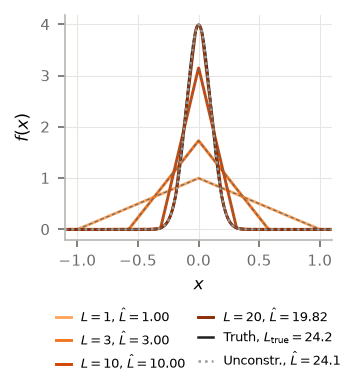

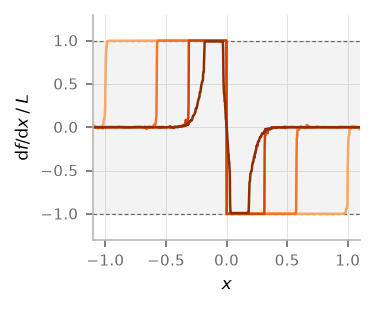

    L      L_hat / L      peak: net | floor      FWHM: net | floor           ISE: net | floor
    1    1.000 ± 0.000     0.999 |  0.999     0.998 |  0.998      1.6472 |    1.6472
    3    1.000 ± 0.000     1.728 |  1.728     0.578 |  0.578      0.9903 |    0.9903
   10    1.000 ± 0.000     3.147 |  3.147     0.313 |  0.313      0.1995 |    0.1995
   20    0.991 ± 0.003     3.988 |  3.989     0.238 |  0.238      0.0026 |    0.0022

Unconstrained: largest slope 24.1 ± 0.1 (L_true = 24.2), peak 3.989 (true 3.989), FWHM 0.233 (true 0.233), ISE 7.05e-07


In [62]:
# Network fits in the same format as the floor fits, in orange (implementation) instead of blue (theory)
net_shades = plt.cm.Oranges(np.linspace(0.4, 0.95, len(L_show)))  # one hue, light -> dark = small -> large L
C_REF = "#9a9893"  # grey for the unconstrained reference, separate from theory (blue) and Lipschitz networks (orange)

with plt.rc_context(REPORT_STYLE):
    # (a) Network fits: mean over seeds, band = spread between seeds, floor as a thin dashed reference
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    truth_line, = ax.plot(x_np, y_np, color=C_TRUE, lw=1.2, label=rf"Truth, $L_\mathrm{{true}} = {L_true:.1f}$")
    network_lines = []
    for L, c in zip(L_show, net_shades):
        ax.fill_between(x_np, net_fits[L].min(0), net_fits[L].max(0), color=c, alpha=0.3, lw=0)
        L_hat = np.abs(net_slopes[L]).max(axis=1).mean()  # largest measured slope, mean over seeds
        line, = ax.plot(x_np, net_fits[L].mean(0), color=c, lw=1.4, label=rf"$L = {L:g}$, $\hat{{L}} = {L_hat:.2f}$")
        network_lines.append(line)
        ax.plot(x_np, floors[L], color=C_MUTED, lw=0.6, ls=(0, (3, 2)))
    L_hat_unc = np.abs(unc_slopes).max(axis=1).mean()
    unconstrained_line, = ax.plot(x_np, unc_fits.mean(0), color=C_REF, lw=1.2, ls=":",
                                  label=rf"Unconstr., $\hat{{L}} = {L_hat_unc:.1f}$")
    #floor_line, = ax.plot([], [], color=C_MUTED, lw=0.6, ls=(0, (3, 2)), label="Floor")  # legend entry only
    ax.set_xlim(x_lo, x_hi)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$f(x)$")
    # The labels with L_hat are too long for the space beside the peak, so the legend goes below the panel
    ax.legend(handles=network_lines + [truth_line, unconstrained_line], loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2, handlelength=1.2, columnspacing=1.0, fontsize=6)
    fig.savefig("Plots/gaussian_network_fits.pdf")
    plt.show()

    # (b) Slope budget: the slope of each network divided by its L. Using the full budget means plateaus at +-1.
    fig, ax = plt.subplots(figsize=PANEL_SIZE)
    ax.axhspan(-1, 1, color=C_MUTED, alpha=0.08, lw=0)
    ax.axhline(1, color=C_MUTED, lw=0.6, ls=(0, (3, 2)))
    ax.axhline(-1, color=C_MUTED, lw=0.6, ls=(0, (3, 2)))
    for L, c in zip(L_show, net_shades):
        ax.plot(x_np, net_slopes[L].mean(0) / L, color=c, lw=1.2)
    ax.set_xlim(x_lo, x_hi); ax.set_ylim(-1.3, 1.3)
    ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$\mathrm{d}f/\mathrm{d}x \;/\; L$")
    # No legend: same colours as panel (a)
    fig.savefig("Plots/gaussian_network_slopes.pdf")
    plt.show()

# --- Table: network (mean ± std over seeds) against the floor
print(f"{'L':>5} {'L_hat / L':>14} {'peak: net | floor':>22} {'FWHM: net | floor':>22} {'ISE: net | floor':>26}")
for L in L_show:
    L_hat = np.abs(net_slopes[L]).max(axis=1) / L
    peaks = net_fits[L].max(axis=1)
    widths = np.array([FWHM_calculation(x_np, f) for f in net_fits[L]])
    ise = np.array([np.trapezoid((f - y_np) ** 2, x_np) for f in net_fits[L]])
    print(f"{L:5g} {L_hat.mean():8.3f} ± {L_hat.std():.3f}"
          f"   {peaks.mean():7.3f} | {floors[L].max():6.3f}"
          f"   {widths.mean():7.3f} | {FWHM_calculation(x_np, floors[L]):6.3f}"
          f"   {ise.mean():9.4f} | {np.trapezoid((floors[L] - y_np) ** 2, x_np):9.4f}")

# Unconstrained reference: no bound, so its largest slope is compared with L_true of the target
L_hat_unc = np.abs(unc_slopes).max(axis=1)
widths_unc = np.array([FWHM_calculation(x_np, f) for f in unc_fits])
ise_unc = np.array([np.trapezoid((f - y_np) ** 2, x_np) for f in unc_fits])
print(f"\nUnconstrained: largest slope {L_hat_unc.mean():.1f} ± {L_hat_unc.std():.1f} (L_true = {L_true:.1f}), "
      f"peak {unc_fits.max(axis=1).mean():.3f} (true {y_np.max():.3f}), "
      f"FWHM {widths_unc.mean():.3f} (true {FWHM_calculation(x_np, y_np):.3f}), ISE {ise_unc.mean():.2e}")

# Added noise response
In this section, we will explore the response of the Lipschitz constrained model to added noise. Particularily we will examine how the model performs when the target function, a Gaussian, is corrupted with sine waves of varying frequencies and amplitudes. Hopefully this corroborates the Spectral Norm regularization paper and shows that Lipschitz networks are even more robust to this tyoe of noise than unconstrained networks.

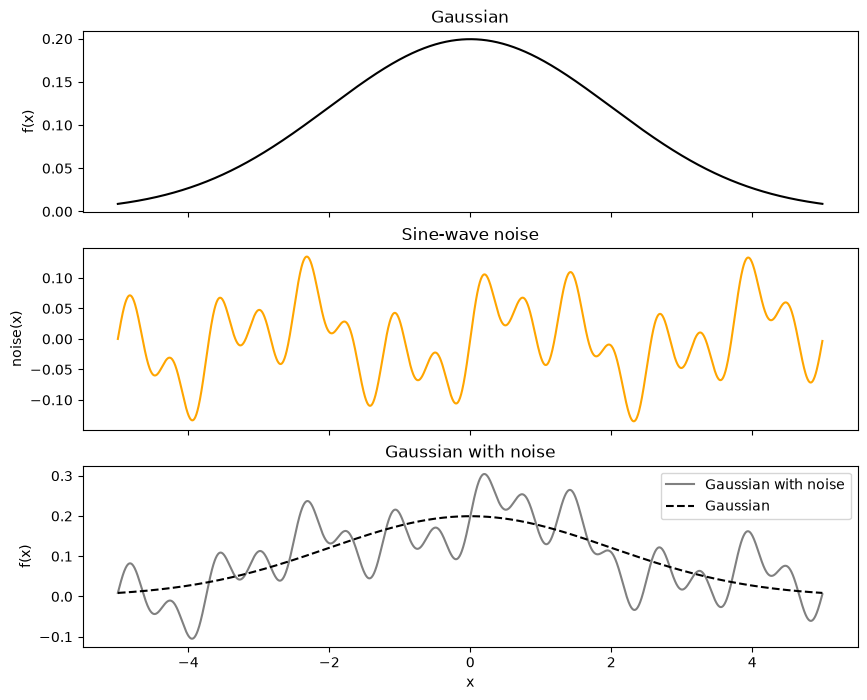

Largest slope of the Gaussian: 0.060
Sine wave with omega =  1.88: amplitude 0.05, needs slope A*omega = 0.094
Sine wave with omega =  5.03: amplitude 0.05, needs slope A*omega = 0.251
Sine wave with omega = 10.05: amplitude 0.05, needs slope A*omega = 0.503


In [152]:
# Sine-wave noise on top of a Gaussian

# PARAMETERS
N = 2000                        # number of points
X_MIN, X_MAX = -5, 5            # range of x
SIGMA = 2.0                     # width of the Gaussian. Wide, so the Gaussian itself only needs slope 0.06,
                                # much less than the sine waves. Otherwise no L can remove the noise without
                                # also cutting into the Gaussian (the bound can only tell signal and noise apart by slope)
AMPLITUDES = [0.05, 0.05, 0.05] # amplitude A of each sine wave
MODES = [3, 8, 16]              # whole number of periods of each sine wave inside [X_MIN, X_MAX]

# Angular frequencies omega = 2*pi*n / (length of the range). With a whole number of periods every sine wave
# sits exactly on one FFT frequency, so it shows up as one clean spike in the spectrum.
FREQUENCIES = [2 * np.pi * n / (X_MAX - X_MIN) for n in MODES]

if len(AMPLITUDES) != len(FREQUENCIES):
    raise ValueError("AMPLITUDES and FREQUENCIES must have the same length (zip would silently drop the extra ones)")


def sine_noise(x, amplitudes, frequencies):
    """
    Adds together sine waves A * sin(omega * x), one for each pair of amplitude and frequency.
    Returns the summed noise at every point in x.
    """
    noise = np.zeros_like(x)
    for A, omega in zip(amplitudes, frequencies):
        noise = noise + A * np.sin(omega * x)
    return noise


# The x grid and the clean Gaussian (unit area)
x = np.linspace(X_MIN, X_MAX, N, endpoint=False)   # no double end point, so the grid is exactly periodic for the FFT
gaussian = 1 / (SIGMA * np.sqrt(2 * np.pi)) * np.exp(-x**2 / (2 * SIGMA**2))

# The noise and the noisy Gaussian
# No rescaling: the amplitudes in AMPLITUDES are the real amplitudes of the waves, so the slopes A*omega below are correct
noise = sine_noise(x, AMPLITUDES, FREQUENCIES)
gaussian_noisy = gaussian + noise

# Plotting the three on top of each other
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axs[0].plot(x, gaussian, color='black')
axs[0].set_title('Gaussian')
axs[0].set_ylabel('f(x)')

axs[1].plot(x, noise, color='orange')
axs[1].set_title('Sine-wave noise')
axs[1].set_ylabel('noise(x)')

axs[2].plot(x, gaussian_noisy, color='grey', label='Gaussian with noise')
axs[2].plot(x, gaussian, color='black', linestyle='--', label='Gaussian')
axs[2].set_title('Gaussian with noise')
axs[2].set_xlabel('x')
axs[2].set_ylabel('f(x)')
axs[2].legend()

plt.show()

# The slope each sine wave needs (A * omega), compared with the slope of the Gaussian itself
print(f"Largest slope of the Gaussian: {gaussian_lipschitz_constant(SIGMA):.3f}")
for A, omega_mode in zip(AMPLITUDES, FREQUENCIES):
    print(f"Sine wave with omega = {omega_mode:5.2f}: amplitude {A}, needs slope A*omega = {A * omega_mode:.3f}")


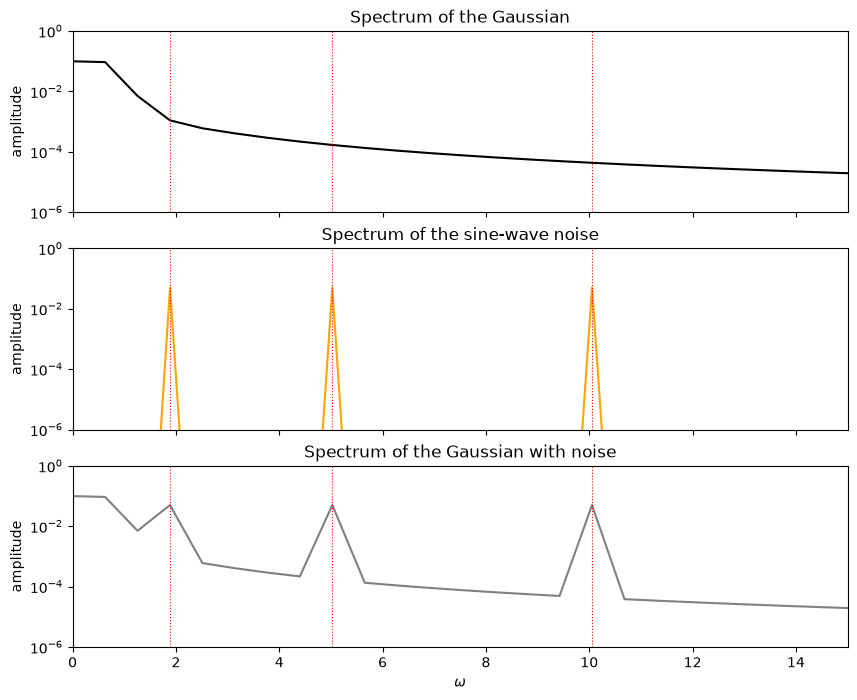

In [153]:
# Fourier spectrum of the Gaussian, the noise and the noisy Gaussian

def fourier_spectrum(x, f):
    """
    Calculates the amplitude spectrum of f, sampled on the evenly spaced grid x.
    Returns the angular frequencies omega and the amplitude at each frequency.
    The amplitudes are scaled so that a term A * sin(omega * x) shows up as a peak of height A.
    """
    n = len(f)
    dx = x[1] - x[0]                          # grid spacing

    fourier = np.fft.rfft(f)                  # Fourier transform (only positive frequencies, since f is real)
    amplitude = 2 * np.abs(fourier) / n       # scale so a sine of amplitude A gives a peak of height A
    amplitude[0] = amplitude[0] / 2           # the constant term (omega = 0) should not be doubled

    frequency = np.fft.rfftfreq(n, d=dx)      # frequencies in cycles per unit of x
    omega = 2 * np.pi * frequency             # convert to angular frequency, to match sin(omega * x)
    return omega, amplitude


# Spectra of the three functions
omega, amplitude_gaussian = fourier_spectrum(x, gaussian)
omega, amplitude_noise = fourier_spectrum(x, noise)
omega, amplitude_noisy = fourier_spectrum(x, gaussian_noisy)

# Plotting the three spectra on top of each other
OMEGA_MAX = 15        # highest frequency to show

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axs[0].plot(omega, amplitude_gaussian, color='black')
axs[0].set_title('Spectrum of the Gaussian')

axs[1].plot(omega, amplitude_noise, color='orange')
axs[1].set_title('Spectrum of the sine-wave noise')

axs[2].plot(omega, amplitude_noisy, color='grey')
axs[2].set_title('Spectrum of the Gaussian with noise')
axs[2].set_xlabel(r'$\omega$')

for ax in axs:
    ax.set_yscale('log')                      # log scale, so small and large amplitudes are both visible
    ax.set_ylim(1e-6, 1)
    ax.set_ylabel('amplitude')
    for omega_noise in FREQUENCIES:           # mark the frequencies of the sine waves
        ax.axvline(omega_noise, color='red', linestyle=':', linewidth=0.8)

axs[0].set_xlim(0, OMEGA_MAX)
plt.show()


In [154]:
# Training Lipschitz networks on the noisy Gaussian, for the same L values as before
L_true_gaussian = gaussian_lipschitz_constant(SIGMA)
print(f"Lipschitz constant of the Gaussian function with sigma={SIGMA}: {L_true_gaussian:.4f}")
L_true_noise = np.max(np.abs(np.gradient(gaussian_noisy, x)))  # approximate Lipschitz constant of the noisy function
print(f"Lipschitz constant of the noisy Gaussian function: {L_true_noise:.4f}")
L_true = max(L_true_gaussian, L_true_noise)

Lipschitz constant of the Gaussian function with sigma=2.0: 0.0605
Lipschitz constant of the noisy Gaussian function: 0.8526


In [155]:
# Training Lipschitz networks on the noisy Gaussian
from Toy_utils import train_full_batch   # plain full-batch Adam training with MSE loss (see Toy_utils.py)

# HYPERPARAMETERS
L_VALUES = [0.1, 0.25, 0.5, 1.0]   # Lipschitz constants to compare. The Gaussian needs 0.06 and the sine waves need
                                    # A*omega = 0.09, 0.25, 0.50, so these L values put the cutoff across the three waves.
                                    # L = 1.0 is above the slope of the whole noisy curve, so it should behave as unconstrained
SEEDS = [0, 1, 2]                  # several seeds per L, to see how much the result varies between runs
HIDDEN_DIM = 64                    # wide enough that an unconstrained network can fit all the sine waves
N_GROUPS = 8
DEPTH = 5
STEPS = 6000                       # number of full-batch training steps
LEARNING_RATE = 3e-3

# Data as torch tensors with shape (N, 1), which is what the networks expect
x_tensor = torch.tensor(x, dtype=torch.float32).unsqueeze(-1)
y_tensor = torch.tensor(gaussian_noisy, dtype=torch.float32).unsqueeze(-1)

# Everything is stored per L and per seed:
#   models[L][seed]      = the trained network (kept, so we can compute slopes later)
#   predictions[L][seed] = the network output on x, as a numpy array
models = {}
predictions = {}

for L in L_VALUES:
    models[L] = {}
    predictions[L] = {}
    for seed in SEEDS:
        torch.manual_seed(seed)    # same seed gives the same starting weights, so every run can be reproduced
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1,
                               n_groups=N_GROUPS, depth=DEPTH, lipschitz_bound=L)
        train_full_batch(model, x_tensor, y_tensor, steps=STEPS, lr=LEARNING_RATE)

        models[L][seed] = model
        with torch.no_grad():
            predictions[L][seed] = model(x_tensor).numpy().ravel()

        mse_noisy = np.mean((predictions[L][seed] - gaussian_noisy) ** 2)   # how well it fits the training data
        mse_clean = np.mean((predictions[L][seed] - gaussian) ** 2)         # how close it gets to the clean Gaussian
        print(f"L = {L}, seed {seed}: MSE to the noisy data = {mse_noisy:.2e}, MSE to the clean Gaussian = {mse_clean:.2e}")

# Unconstrained reference: same size and training, no Lipschitz bound
models_unconstrained = {}
predictions_unconstrained = {}

for seed in SEEDS:
    torch.manual_seed(seed)
    model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth=DEPTH)
    train_full_batch(model, x_tensor, y_tensor, steps=STEPS, lr=LEARNING_RATE)

    models_unconstrained[seed] = model
    with torch.no_grad():
        predictions_unconstrained[seed] = model(x_tensor).numpy().ravel()

    mse_noisy = np.mean((predictions_unconstrained[seed] - gaussian_noisy) ** 2)
    mse_clean = np.mean((predictions_unconstrained[seed] - gaussian) ** 2)
    print(f"Unconstrained, seed {seed}: MSE to the noisy data = {mse_noisy:.2e}, MSE to the clean Gaussian = {mse_clean:.2e}")


L = 0.1, seed 0: MSE to the noisy data = 1.99e-03, MSE to the clean Gaussian = 7.73e-04
L = 0.1, seed 1: MSE to the noisy data = 2.02e-03, MSE to the clean Gaussian = 7.89e-04
L = 0.1, seed 2: MSE to the noisy data = 2.02e-03, MSE to the clean Gaussian = 8.27e-04
L = 0.25, seed 0: MSE to the noisy data = 6.95e-04, MSE to the clean Gaussian = 1.93e-03
L = 0.25, seed 1: MSE to the noisy data = 7.31e-04, MSE to the clean Gaussian = 1.96e-03
L = 0.25, seed 2: MSE to the noisy data = 7.47e-04, MSE to the clean Gaussian = 1.94e-03
L = 0.5, seed 0: MSE to the noisy data = 1.75e-04, MSE to the clean Gaussian = 3.04e-03
L = 0.5, seed 1: MSE to the noisy data = 2.47e-04, MSE to the clean Gaussian = 2.96e-03
L = 0.5, seed 2: MSE to the noisy data = 1.59e-04, MSE to the clean Gaussian = 3.04e-03
L = 1.0, seed 0: MSE to the noisy data = 9.18e-05, MSE to the clean Gaussian = 3.43e-03
L = 1.0, seed 1: MSE to the noisy data = 5.39e-05, MSE to the clean Gaussian = 3.58e-03
L = 1.0, seed 2: MSE to the n

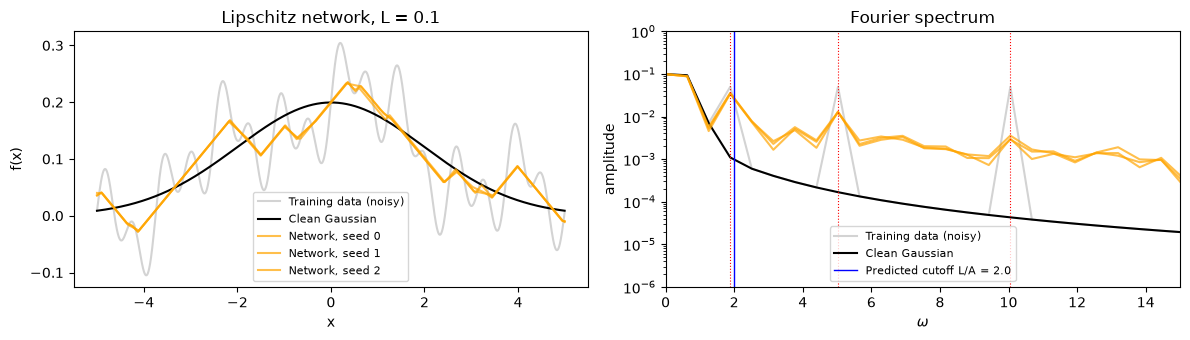

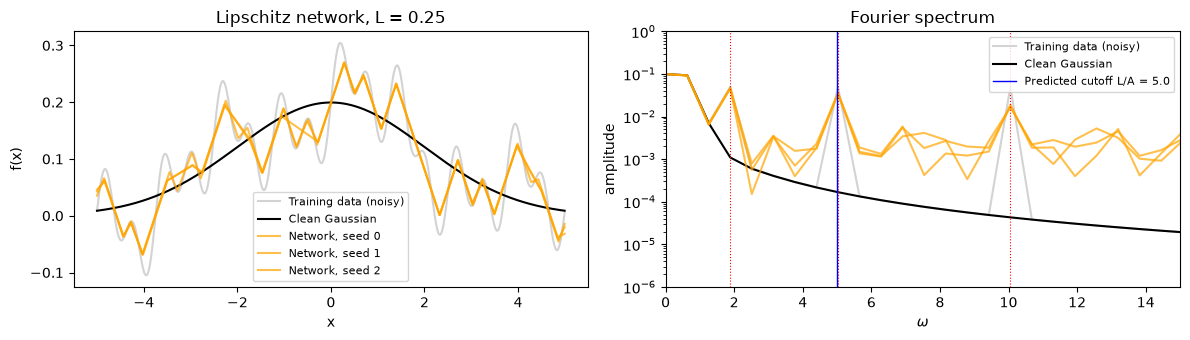

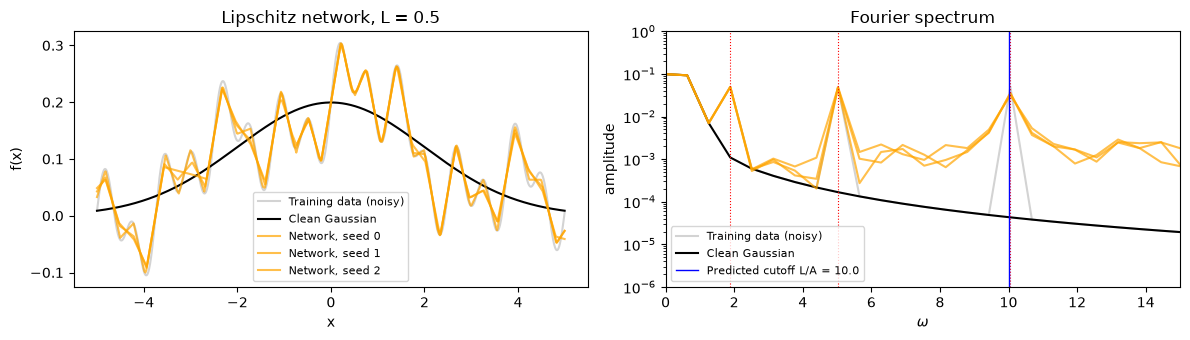

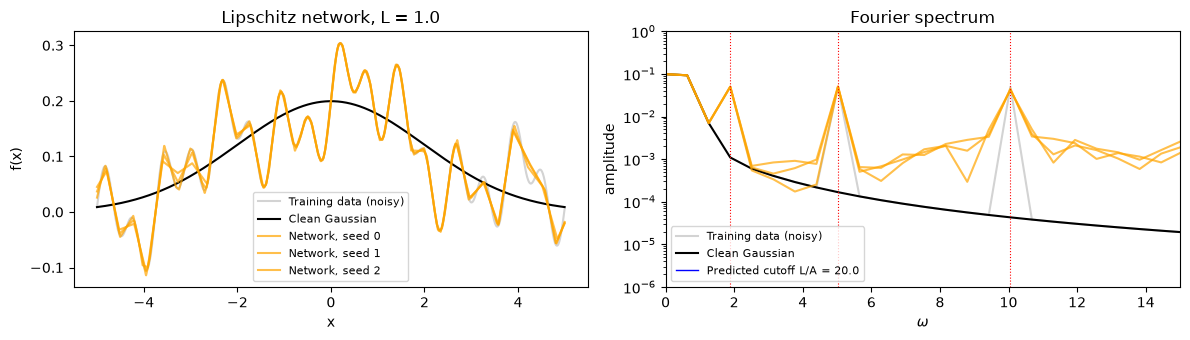

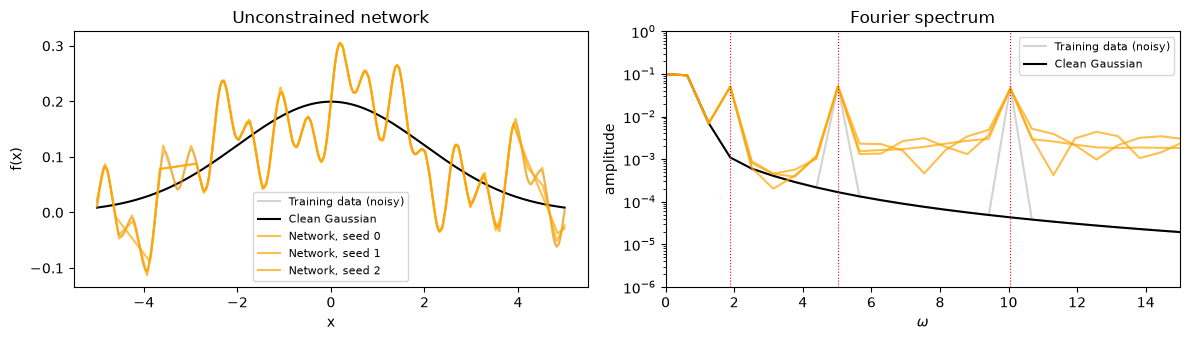

In [156]:
# Plotting the predictions next to their Fourier spectra

def plot_prediction_and_spectrum(x, predictions_per_seed, title, L=None, omega_max=15):
    """
    Plots one network (all seeds) next to its Fourier spectrum.
    Left: the noisy training data, the clean Gaussian and the network output for every seed.
    Right: the spectra of the same curves.
    If L is given, the predicted cutoff omega = L / A is marked in the spectrum.
    """
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))

    # Spectra of the training data and the clean Gaussian
    omega, amplitude_noisy = fourier_spectrum(x, gaussian_noisy)
    omega, amplitude_gaussian = fourier_spectrum(x, gaussian)

    # --- Left: the functions
    axs[0].plot(x, gaussian_noisy, color='lightgrey', label='Training data (noisy)')
    axs[0].plot(x, gaussian, color='black', label='Clean Gaussian')
    for seed, prediction in predictions_per_seed.items():
        axs[0].plot(x, prediction, color='orange', alpha=0.7, label=f'Network, seed {seed}')
    axs[0].set_xlabel('x')
    axs[0].set_ylabel('f(x)')
    axs[0].set_title(title)
    axs[0].legend(fontsize=8)

    # --- Right: the spectra
    axs[1].plot(omega, amplitude_noisy, color='lightgrey', label='Training data (noisy)')
    axs[1].plot(omega, amplitude_gaussian, color='black', label='Clean Gaussian')
    for seed, prediction in predictions_per_seed.items():
        omega, amplitude_prediction = fourier_spectrum(x, prediction)
        axs[1].plot(omega, amplitude_prediction, color='orange', alpha=0.7)
    for omega_noise in FREQUENCIES:               # frequencies of the sine waves
        axs[1].axvline(omega_noise, color='red', linestyle=':', linewidth=0.8)
    if L is not None:                             # predicted cutoff: a sine wave needs slope A * omega, so the bound cuts at omega = L / A
        omega_cutoff = L / AMPLITUDES[0]          # (assumes all sine waves have the same amplitude, as in the setup above)
        axs[1].axvline(omega_cutoff, color='blue', linewidth=1.0, label=f'Predicted cutoff L/A = {omega_cutoff:.1f}')
    axs[1].set_yscale('log')
    axs[1].set_ylim(1e-6, 1)
    axs[1].set_xlim(0, omega_max)
    axs[1].set_xlabel(r'$\omega$')
    axs[1].set_ylabel('amplitude')
    axs[1].set_title('Fourier spectrum')
    axs[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()


# One figure per Lipschitz constant, then the unconstrained reference
for L in L_VALUES:
    plot_prediction_and_spectrum(x, predictions[L], title=f'Lipschitz network, L = {L}', L=L)

plot_prediction_and_spectrum(x, predictions_unconstrained, title='Unconstrained network')


Fraction of each sine wave that survives (mean ± std over seeds)
L = 0.1:
   omega =  1.88, A*omega/L = 0.94: 0.70 ± 0.01
   omega =  5.03, A*omega/L = 2.51: 0.26 ± 0.00
   omega = 10.05, A*omega/L = 5.03: 0.06 ± 0.01
L = 0.25:
   omega =  1.88, A*omega/L = 0.38: 0.93 ± 0.00
   omega =  5.03, A*omega/L = 1.01: 0.71 ± 0.01
   omega = 10.05, A*omega/L = 2.01: 0.35 ± 0.02
L = 0.5:
   omega =  1.88, A*omega/L = 0.19: 0.99 ± 0.00
   omega =  5.03, A*omega/L = 0.50: 0.96 ± 0.01
   omega = 10.05, A*omega/L = 1.01: 0.68 ± 0.04
L = 1.0:
   omega =  1.88, A*omega/L = 0.09: 1.00 ± 0.00
   omega =  5.03, A*omega/L = 0.25: 1.01 ± 0.00
   omega = 10.05, A*omega/L = 0.50: 0.86 ± 0.03
Unconstrained:
   omega =  1.88: 1.00 ± 0.00
   omega =  5.03: 1.02 ± 0.00
   omega = 10.05: 0.91 ± 0.02

MSE to the clean Gaussian (lower = better denoising)
   noisy training data itself: 3.75e-03
   L = 0.1: 7.96e-04 ± 2.3e-05
   L = 0.25: 1.94e-03 ± 1.0e-05
   L = 0.5: 3.01e-03 ± 3.6e-05
   L = 1.0: 3.50e-03 ± 6.3e-0

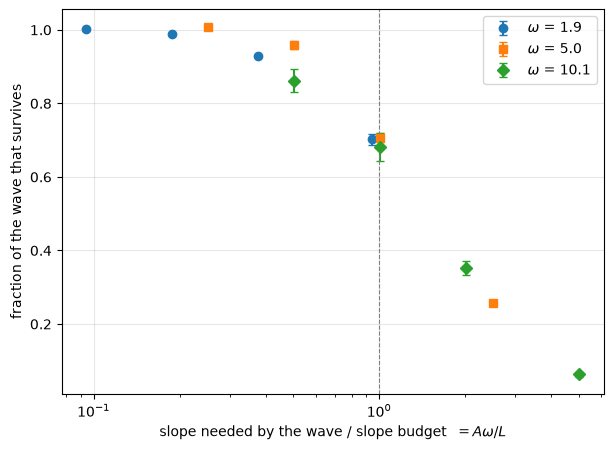

In [157]:
# Evaluation: how much of each sine wave survives in the network output, and how close the networks get to the clean Gaussian

def mode_amplitude(x, f, omega_mode):
    """Amplitude of the sine wave with angular frequency omega_mode in f, read from the Fourier spectrum."""
    omega, amplitude = fourier_spectrum(x, f)
    index = np.argmin(np.abs(omega - omega_mode))   # the FFT frequency closest to omega_mode (exact, since the modes sit on the grid)
    return amplitude[index]


# Fraction of each sine wave that survives: amplitude in the network output divided by the amplitude in the data
print("Fraction of each sine wave that survives (mean ± std over seeds)")
for L in L_VALUES:
    print(f"L = {L}:")
    for A, omega_mode in zip(AMPLITUDES, FREQUENCIES):
        fractions = []
        for seed in SEEDS:
            fractions.append(mode_amplitude(x, predictions[L][seed], omega_mode) / A)
        print(f"   omega = {omega_mode:5.2f}, A*omega/L = {A * omega_mode / L:4.2f}: {np.mean(fractions):.2f} ± {np.std(fractions):.2f}")

print("Unconstrained:")
for A, omega_mode in zip(AMPLITUDES, FREQUENCIES):
    fractions = []
    for seed in SEEDS:
        fractions.append(mode_amplitude(x, predictions_unconstrained[seed], omega_mode) / A)
    print(f"   omega = {omega_mode:5.2f}: {np.mean(fractions):.2f} ± {np.std(fractions):.2f}")

# Denoising: MSE against the CLEAN Gaussian. The noisy data itself has MSE = mean(noise^2)
print("\nMSE to the clean Gaussian (lower = better denoising)")
print(f"   noisy training data itself: {np.mean(noise ** 2):.2e}")
for L in L_VALUES:
    mse_clean = []
    for seed in SEEDS:
        mse_clean.append(np.mean((predictions[L][seed] - gaussian) ** 2))
    print(f"   L = {L}: {np.mean(mse_clean):.2e} ± {np.std(mse_clean):.1e}")
mse_clean = []
for seed in SEEDS:
    mse_clean.append(np.mean((predictions_unconstrained[seed] - gaussian) ** 2))
print(f"   unconstrained: {np.mean(mse_clean):.2e} ± {np.std(mse_clean):.1e}")

# Summary plot: fraction that survives against the slope the wave needs relative to the budget, A*omega / L.
# If the slope is what matters, all waves and all L should fall on one curve, dropping around A*omega / L = 1.
plt.figure(figsize=(7, 5))
markers = ['o', 's', 'D']
for A, omega_mode, marker in zip(AMPLITUDES, FREQUENCIES, markers):
    slope_ratios = []
    mean_fractions = []
    std_fractions = []
    for L in L_VALUES:
        fractions = []
        for seed in SEEDS:
            fractions.append(mode_amplitude(x, predictions[L][seed], omega_mode) / A)
        slope_ratios.append(A * omega_mode / L)
        mean_fractions.append(np.mean(fractions))
        std_fractions.append(np.std(fractions))
    plt.errorbar(slope_ratios, mean_fractions, yerr=std_fractions, fmt=marker, capsize=3, label=f'$\\omega$ = {omega_mode:.1f}')
plt.axvline(1, color='grey', linestyle='--', linewidth=0.8)
plt.xscale('log')
plt.xlabel(r'slope needed by the wave / slope budget  $= A\omega / L$')
plt.ylabel('fraction of the wave that survives')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Network              noise removed    remaining error / noise
L = 0.1              81.2 ±  0.6 %           0.212 ± 0.006
L = 0.25             50.4 ±  0.3 %           0.518 ± 0.003
L = 0.5              21.3 ±  1.2 %           0.804 ± 0.010
L = 1.0               7.9 ±  1.8 %           0.933 ± 0.017
Unconstrained         3.8 ±  0.9 %           0.977 ± 0.005


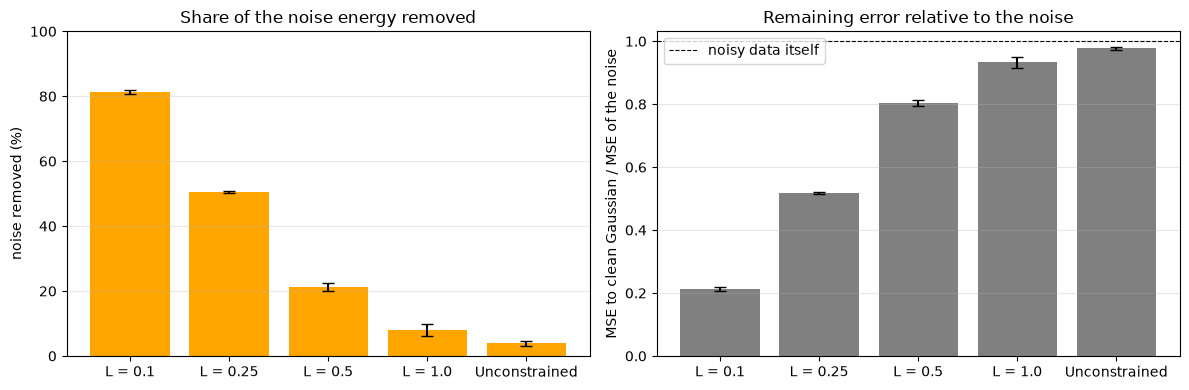

In [158]:
# How much of the noise does each network remove?
# Two numbers per network (mean ± std over seeds):
#  1) Noise removed: the share of the noise energy at the noise frequencies that is gone from the output.
#     A sine wave with amplitude a carries energy a^2 / 2, so we compare the squared amplitudes:
#         noise removed = 1 - sum(amplitude left in the output^2) / sum(amplitude in the data^2)
#  2) Remaining error relative to the noise: mean((output - clean Gaussian)^2) / mean(noise^2).
#     This counts everything that is still wrong: leftover noise, the extra frequencies created when the bound
#     clips a wave, and any distortion of the Gaussian itself. Below 1 means the output is closer to the clean
#     Gaussian than the noisy data was.

noise_energy_in_data = np.sum(np.array(AMPLITUDES) ** 2)   # sum of squared amplitudes of the noise waves
noise_mse_in_data = np.mean(noise ** 2)                     # mean squared noise in the data


def noise_removed(prediction):
    """Share of the noise energy (at the noise frequencies) that is no longer in the prediction."""
    energy_left = 0.0
    for omega_mode in FREQUENCIES:
        energy_left = energy_left + mode_amplitude(x, prediction, omega_mode) ** 2
    return 1 - energy_left / noise_energy_in_data


def remaining_error(prediction):
    """Mean squared distance to the clean Gaussian, relative to the mean squared noise in the data."""
    return np.mean((prediction - gaussian) ** 2) / noise_mse_in_data


# Collect the numbers for every network
names = []
removed_mean, removed_std = [], []
error_mean, error_std = [], []

for L in L_VALUES:
    removed = [noise_removed(predictions[L][seed]) for seed in SEEDS]
    error = [remaining_error(predictions[L][seed]) for seed in SEEDS]
    names.append(f'L = {L}')
    removed_mean.append(np.mean(removed)); removed_std.append(np.std(removed))
    error_mean.append(np.mean(error)); error_std.append(np.std(error))

removed = [noise_removed(predictions_unconstrained[seed]) for seed in SEEDS]
error = [remaining_error(predictions_unconstrained[seed]) for seed in SEEDS]
names.append('Unconstrained')
removed_mean.append(np.mean(removed)); removed_std.append(np.std(removed))
error_mean.append(np.mean(error)); error_std.append(np.std(error))

# Table
print(f"{'Network':15s} {'noise removed':>18s} {'remaining error / noise':>26s}")
for i in range(len(names)):
    print(f"{names[i]:15s} {100 * removed_mean[i]:9.1f} ± {100 * removed_std[i]:4.1f} %"
          f" {error_mean[i]:15.3f} ± {error_std[i]:.3f}")

# Bar plots of the two numbers
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].bar(names, 100 * np.array(removed_mean), yerr=100 * np.array(removed_std), capsize=4, color='orange')
axs[0].set_ylabel('noise removed (%)')
axs[0].set_title('Share of the noise energy removed')
axs[0].set_ylim(0, 100)

axs[1].bar(names, error_mean, yerr=error_std, capsize=4, color='grey')
axs[1].axhline(1, color='black', linestyle='--', linewidth=0.8, label='noisy data itself')
axs[1].set_ylabel('MSE to clean Gaussian / MSE of the noise')
axs[1].set_title('Remaining error relative to the noise')
axs[1].legend()

for ax in axs:
    ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

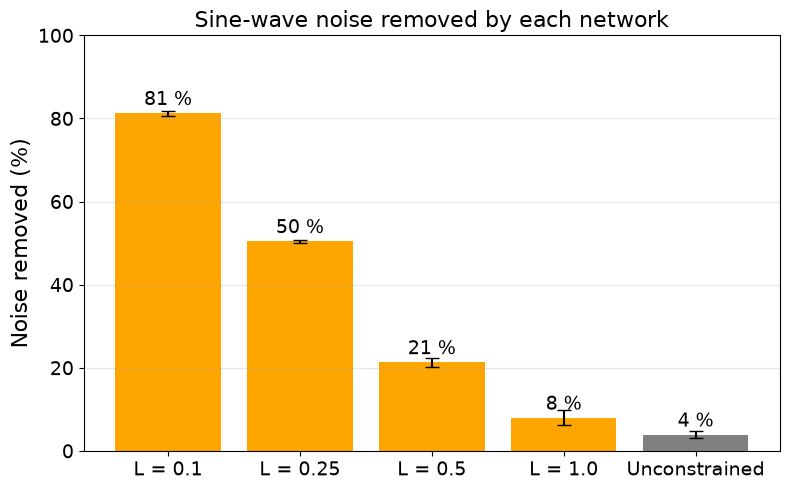

In [168]:
# Bar plot of the noise removed for the sine-wave noise, on its own (for the presentation)
# Recalculated here from the sine-wave predictions, because the white-noise section reuses the names removed_mean etc.

names_sine = []
removed_sine_mean = []
removed_sine_std = []

for L in L_VALUES:
    removed = []
    for seed in SEEDS:
        removed.append(100 * noise_removed(predictions[L][seed]))   # noise_removed is defined in the cell above
    names_sine.append(f'L = {L}')
    removed_sine_mean.append(np.mean(removed))
    removed_sine_std.append(np.std(removed))

removed = []
for seed in SEEDS:
    removed.append(100 * noise_removed(predictions_unconstrained[seed]))
names_sine.append('Unconstrained')
removed_sine_mean.append(np.mean(removed))
removed_sine_std.append(np.std(removed))

# Lipschitz networks in orange, the unconstrained reference in grey
bar_colors = ['orange'] * len(L_VALUES) + ['grey']

plt.figure(figsize=(8, 5))
plt.bar(names_sine, removed_sine_mean, yerr=removed_sine_std, capsize=5, color=bar_colors)

# Write the value on top of each bar
for i in range(len(names_sine)):
    plt.text(i, removed_sine_mean[i] + 2, f'{removed_sine_mean[i]:.0f} %', ha='center', fontsize=14)

plt.ylabel('Noise removed (%)', fontsize=16)
plt.title('Sine-wave noise removed by each network', fontsize=16)
plt.ylim(0, 100)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()

#plt.savefig('Plots/sine_noise_removed.pdf')            # vector version, for LaTeX
#plt.savefig('Plots/sine_noise_removed.png', dpi=300)   # high-resolution picture, for slides
plt.show()


# White noise response
The same set-up as the sine-wave section: the same Gaussian ($\sigma = 2$), grid, Lipschitz constants, seeds and networks. The only difference is the noise. Instead of three sine waves, every point gets its own independent random noise (white noise). The noise level is chosen so that the noise has the *same power* (mean squared noise) as the three sine waves, so the two sections can be compared directly.

White noise has no particular frequency: its energy is spread evenly over all frequencies. Most of it is therefore very fast, and needs slopes of roughly $\sqrt{2}\,\sigma_\text{noise}/\Delta x \approx 17$, far above any $L$ we use. Only the slow part of the noise has small enough slopes to pass the bound. We therefore expect the Lipschitz networks to remove most of the noise, and the unconstrained network to follow as much of it as its capacity and training allow.

Since there are no individual waves to follow, the evaluation is adapted:
- instead of the fraction of each wave that survives, we measure the fraction of the noise that is kept in each frequency band,
- instead of the energy left at the noise frequencies, we measure how much of the actual noise pattern the network copies.

Uses `fourier_spectrum` from the sine-wave section, so run that section first. Training takes about 7 minutes.

Noise standard deviation: 0.0612 (mean squared noise 3.75e-03)
Typical slope of the noise between neighbouring points: 17.3
Largest slope of the Gaussian: 0.060
Largest slope of the noisy data: 31.1


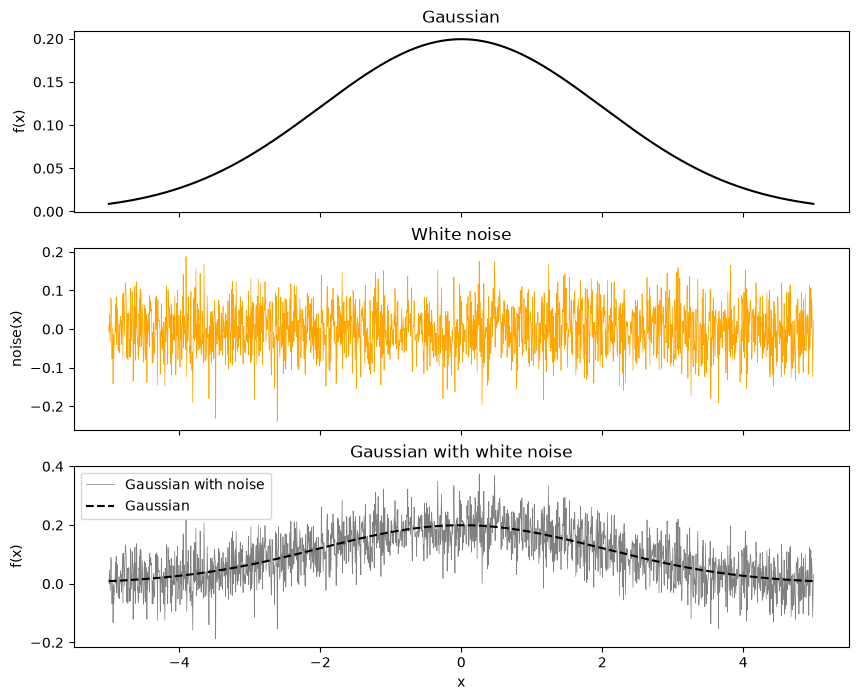

In [159]:
# White noise on top of the same Gaussian

# PARAMETERS (same grid and Gaussian as the sine-wave section, so the two can be compared directly)
N = 2000                                # number of points
X_MIN, X_MAX = -5, 5                    # range of x
SIGMA = 2.0                             # width of the Gaussian
NOISE_STD = np.sqrt(3 * 0.05 ** 2 / 2)  # standard deviation of the noise. Gives the same noise power (mean squared noise)
                                        # as three sine waves of amplitude 0.05, which have mean squared noise 3 * 0.05^2 / 2
NOISE_SEED = 0                          # fixed seed, so the same noise pattern is used every time the cell is run

# The x grid and the clean Gaussian (unit area)
x_white = np.linspace(X_MIN, X_MAX, N, endpoint=False)
gaussian_white = 1 / (SIGMA * np.sqrt(2 * np.pi)) * np.exp(-x_white ** 2 / (2 * SIGMA ** 2))

# White noise: an independent random number at every point
rng = np.random.default_rng(NOISE_SEED)
white_noise = NOISE_STD * rng.standard_normal(N)
gaussian_white_noisy = gaussian_white + white_noise

# Slopes: neighbouring noise values are independent, so a typical jump between them is sqrt(2) * NOISE_STD over one grid step
dx_white = x_white[1] - x_white[0]
print(f"Noise standard deviation: {NOISE_STD:.4f} (mean squared noise {np.mean(white_noise ** 2):.2e})")
print(f"Typical slope of the noise between neighbouring points: {np.sqrt(2) * NOISE_STD / dx_white:.1f}")
print(f"Largest slope of the Gaussian: {gaussian_lipschitz_constant(SIGMA):.3f}")
print(f"Largest slope of the noisy data: {np.max(np.abs(np.gradient(gaussian_white_noisy, x_white))):.1f}")

# Plotting the three on top of each other
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axs[0].plot(x_white, gaussian_white, color='black')
axs[0].set_title('Gaussian')
axs[0].set_ylabel('f(x)')

axs[1].plot(x_white, white_noise, color='orange', linewidth=0.5)
axs[1].set_title('White noise')
axs[1].set_ylabel('noise(x)')

axs[2].plot(x_white, gaussian_white_noisy, color='grey', linewidth=0.5, label='Gaussian with noise')
axs[2].plot(x_white, gaussian_white, color='black', linestyle='--', label='Gaussian')
axs[2].set_title('Gaussian with white noise')
axs[2].set_xlabel('x')
axs[2].set_ylabel('f(x)')
axs[2].legend()

plt.show()

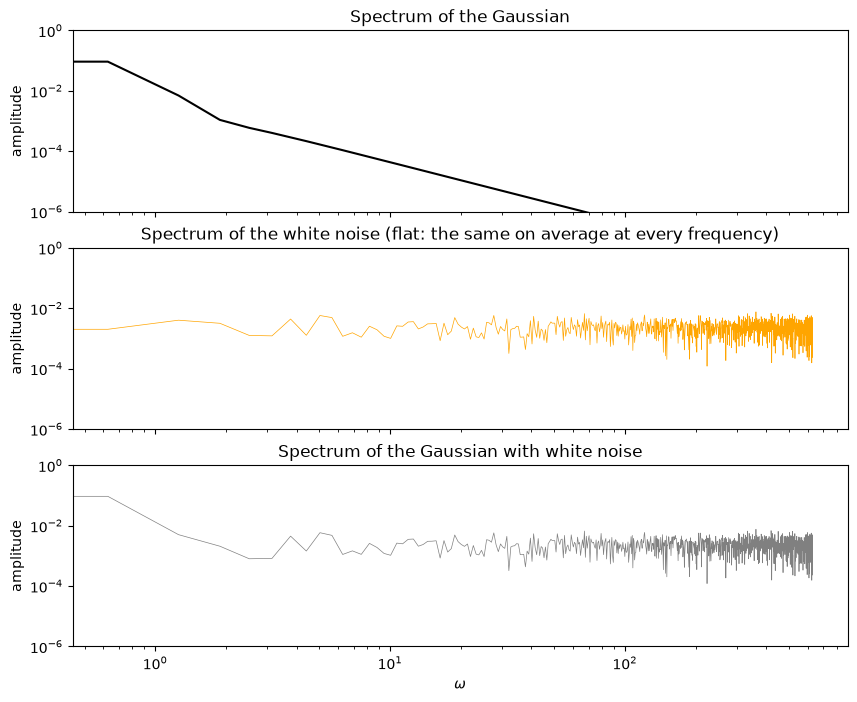

In [160]:
# Fourier spectrum of the Gaussian, the white noise and the noisy Gaussian (fourier_spectrum is defined in the sine-wave section)

omega_white, amplitude_gaussian_white = fourier_spectrum(x_white, gaussian_white)
omega_white, amplitude_white_noise = fourier_spectrum(x_white, white_noise)
omega_white, amplitude_white_noisy = fourier_spectrum(x_white, gaussian_white_noisy)

# White noise reaches all the way up to the highest frequency the grid can show, so both axes are logarithmic
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axs[0].plot(omega_white, amplitude_gaussian_white, color='black')
axs[0].set_title('Spectrum of the Gaussian')

axs[1].plot(omega_white, amplitude_white_noise, color='orange', linewidth=0.5)
axs[1].set_title('Spectrum of the white noise (flat: the same on average at every frequency)')

axs[2].plot(omega_white, amplitude_white_noisy, color='grey', linewidth=0.5)
axs[2].set_title('Spectrum of the Gaussian with white noise')
axs[2].set_xlabel(r'$\omega$')

for ax in axs:
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_ylim(1e-6, 1)
    ax.set_ylabel('amplitude')

plt.show()

In [161]:
# Training Lipschitz networks on the Gaussian with white noise (same networks and settings as the sine-wave section)
from Toy_utils import train_full_batch   # plain full-batch Adam training with MSE loss (see Toy_utils.py)

# HYPERPARAMETERS (the same values as in the sine-wave section)
L_VALUES = [0.1, 0.25, 0.5, 1.0]   # Lipschitz constants to compare. The Gaussian itself needs slope 0.06
SEEDS = [0, 1, 2]                  # several seeds per L, to see how much the result varies between runs
HIDDEN_DIM = 64
N_GROUPS = 8
DEPTH = 5
STEPS = 6000                       # number of full-batch training steps
LEARNING_RATE = 3e-3

# Data as torch tensors with shape (N, 1), which is what the networks expect
x_white_tensor = torch.tensor(x_white, dtype=torch.float32).unsqueeze(-1)
y_white_tensor = torch.tensor(gaussian_white_noisy, dtype=torch.float32).unsqueeze(-1)

# Everything is stored per L and per seed, with its own names so the sine-wave results are not overwritten:
#   models_white[L][seed]      = the trained network
#   predictions_white[L][seed] = the network output on x_white, as a numpy array
models_white = {}
predictions_white = {}

for L in L_VALUES:
    models_white[L] = {}
    predictions_white[L] = {}
    for seed in SEEDS:
        torch.manual_seed(seed)    # same seed gives the same starting weights, so every run can be reproduced
        model = LipschitzModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1,
                               n_groups=N_GROUPS, depth=DEPTH, lipschitz_bound=L)
        train_full_batch(model, x_white_tensor, y_white_tensor, steps=STEPS, lr=LEARNING_RATE)

        models_white[L][seed] = model
        with torch.no_grad():
            predictions_white[L][seed] = model(x_white_tensor).numpy().ravel()

        mse_noisy = np.mean((predictions_white[L][seed] - gaussian_white_noisy) ** 2)   # how well it fits the training data
        mse_clean = np.mean((predictions_white[L][seed] - gaussian_white) ** 2)         # how close it gets to the clean Gaussian
        print(f"L = {L}, seed {seed}: MSE to the noisy data = {mse_noisy:.2e}, MSE to the clean Gaussian = {mse_clean:.2e}")

# Unconstrained reference: same size and training, no Lipschitz bound
models_white_unconstrained = {}
predictions_white_unconstrained = {}

for seed in SEEDS:
    torch.manual_seed(seed)
    model = UnconstrainedModel(input_dim=1, hidden_dim=HIDDEN_DIM, output_dim=1, depth=DEPTH)
    train_full_batch(model, x_white_tensor, y_white_tensor, steps=STEPS, lr=LEARNING_RATE)

    models_white_unconstrained[seed] = model
    with torch.no_grad():
        predictions_white_unconstrained[seed] = model(x_white_tensor).numpy().ravel()

    mse_noisy = np.mean((predictions_white_unconstrained[seed] - gaussian_white_noisy) ** 2)
    mse_clean = np.mean((predictions_white_unconstrained[seed] - gaussian_white) ** 2)
    print(f"Unconstrained, seed {seed}: MSE to the noisy data = {mse_noisy:.2e}, MSE to the clean Gaussian = {mse_clean:.2e}")

L = 0.1, seed 0: MSE to the noisy data = 3.67e-03, MSE to the clean Gaussian = 5.47e-05
L = 0.1, seed 1: MSE to the noisy data = 3.67e-03, MSE to the clean Gaussian = 5.66e-05
L = 0.1, seed 2: MSE to the noisy data = 3.67e-03, MSE to the clean Gaussian = 5.10e-05
L = 0.25, seed 0: MSE to the noisy data = 3.64e-03, MSE to the clean Gaussian = 7.83e-05
L = 0.25, seed 1: MSE to the noisy data = 3.64e-03, MSE to the clean Gaussian = 7.79e-05
L = 0.25, seed 2: MSE to the noisy data = 3.64e-03, MSE to the clean Gaussian = 7.28e-05
L = 0.5, seed 0: MSE to the noisy data = 3.62e-03, MSE to the clean Gaussian = 9.55e-05
L = 0.5, seed 1: MSE to the noisy data = 3.63e-03, MSE to the clean Gaussian = 8.98e-05
L = 0.5, seed 2: MSE to the noisy data = 3.62e-03, MSE to the clean Gaussian = 9.15e-05
L = 1.0, seed 0: MSE to the noisy data = 3.60e-03, MSE to the clean Gaussian = 1.21e-04
L = 1.0, seed 1: MSE to the noisy data = 3.60e-03, MSE to the clean Gaussian = 1.18e-04
L = 1.0, seed 2: MSE to the n

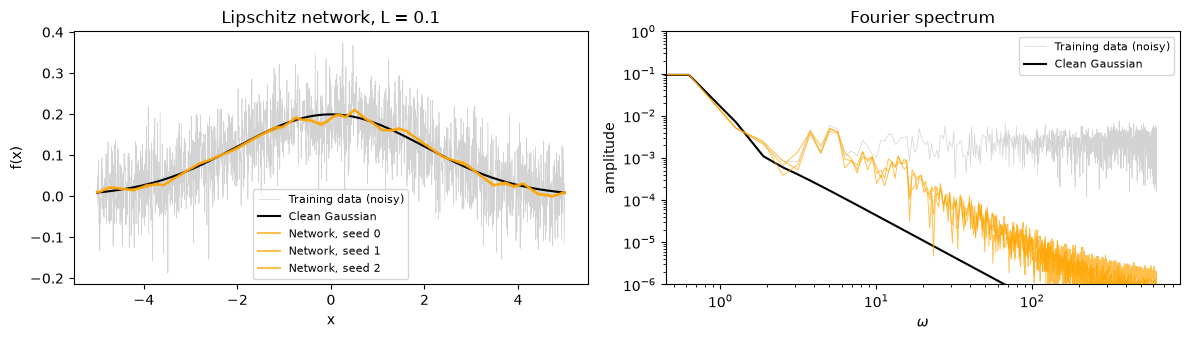

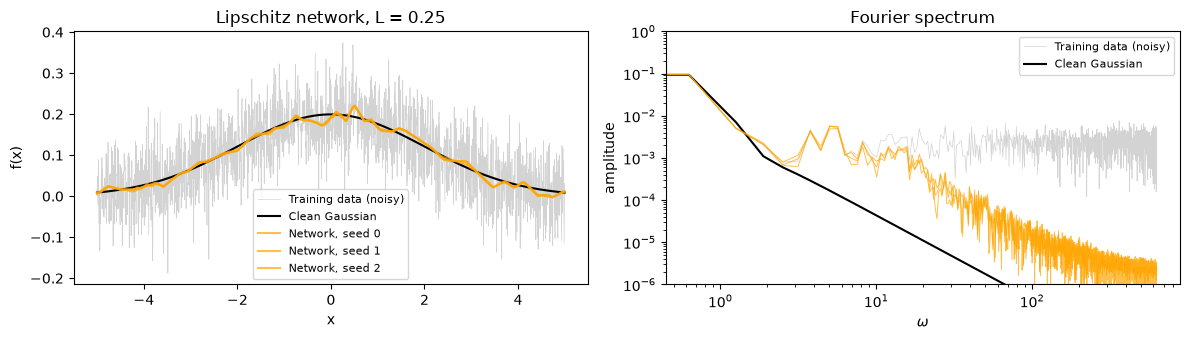

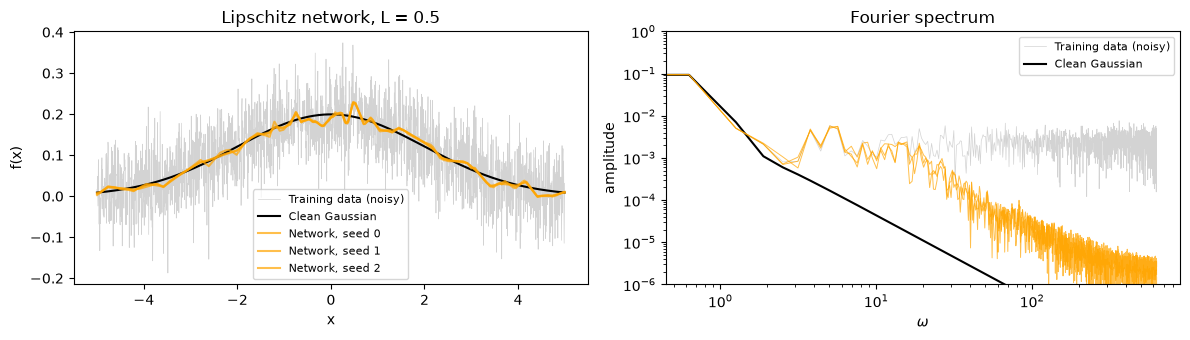

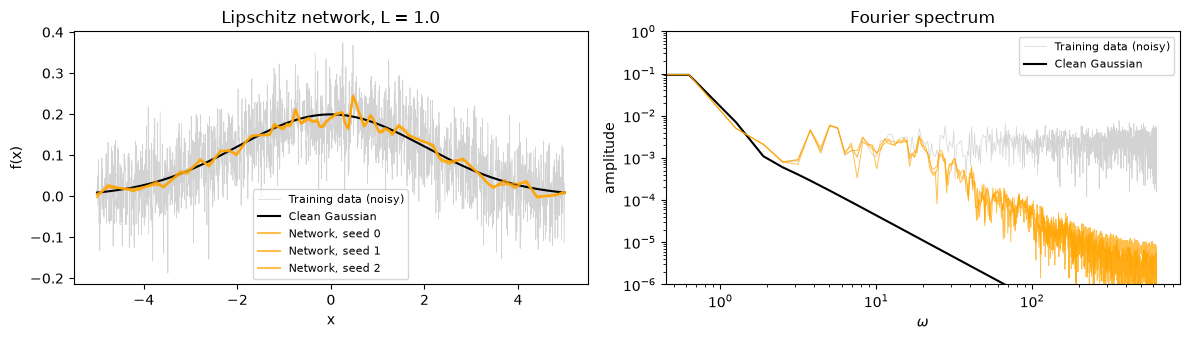

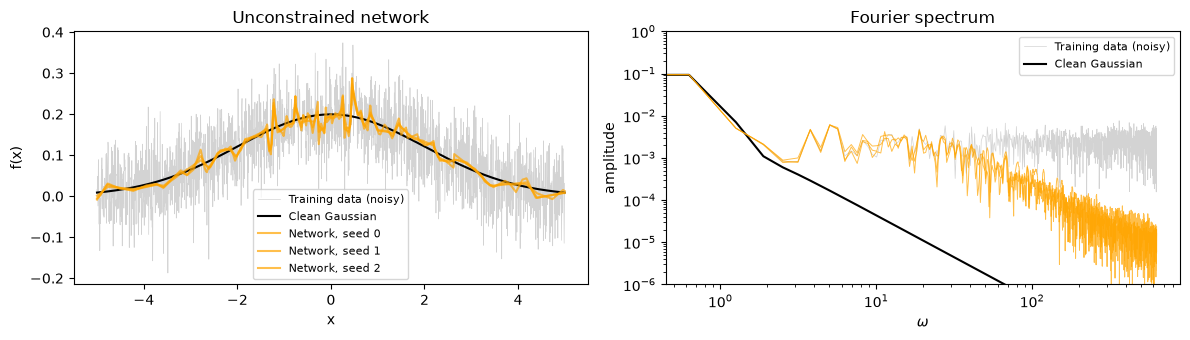

In [162]:
# Plotting the predictions next to their Fourier spectra (white noise)

def plot_prediction_and_spectrum_white(predictions_per_seed, title):
    """
    Plots one network (all seeds) next to its Fourier spectrum, for the white-noise data.
    Left: the noisy training data, the clean Gaussian and the network output for every seed.
    Right: the spectra of the same curves (both axes logarithmic, since the noise covers all frequencies).
    """
    fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))

    # --- Left: the functions
    axs[0].plot(x_white, gaussian_white_noisy, color='lightgrey', linewidth=0.5, label='Training data (noisy)')
    axs[0].plot(x_white, gaussian_white, color='black', label='Clean Gaussian')
    for seed, prediction in predictions_per_seed.items():
        axs[0].plot(x_white, prediction, color='orange', alpha=0.7, label=f'Network, seed {seed}')
    axs[0].set_xlabel('x')
    axs[0].set_ylabel('f(x)')
    axs[0].set_title(title)
    axs[0].legend(fontsize=8)

    # --- Right: the spectra
    axs[1].plot(omega_white, amplitude_white_noisy, color='lightgrey', linewidth=0.5, label='Training data (noisy)')
    axs[1].plot(omega_white, amplitude_gaussian_white, color='black', label='Clean Gaussian')
    for seed, prediction in predictions_per_seed.items():
        omega, amplitude_prediction = fourier_spectrum(x_white, prediction)
        axs[1].plot(omega, amplitude_prediction, color='orange', alpha=0.7, linewidth=0.7)
    axs[1].set_xscale('log')
    axs[1].set_yscale('log')
    axs[1].set_ylim(1e-6, 1)
    axs[1].set_xlabel(r'$\omega$')
    axs[1].set_ylabel('amplitude')
    axs[1].set_title('Fourier spectrum')
    axs[1].legend(fontsize=8)

    plt.tight_layout()
    plt.show()


# One figure per Lipschitz constant, then the unconstrained reference
for L in L_VALUES:
    plot_prediction_and_spectrum_white(predictions_white[L], title=f'Lipschitz network, L = {L}')

plot_prediction_and_spectrum_white(predictions_white_unconstrained, title='Unconstrained network')

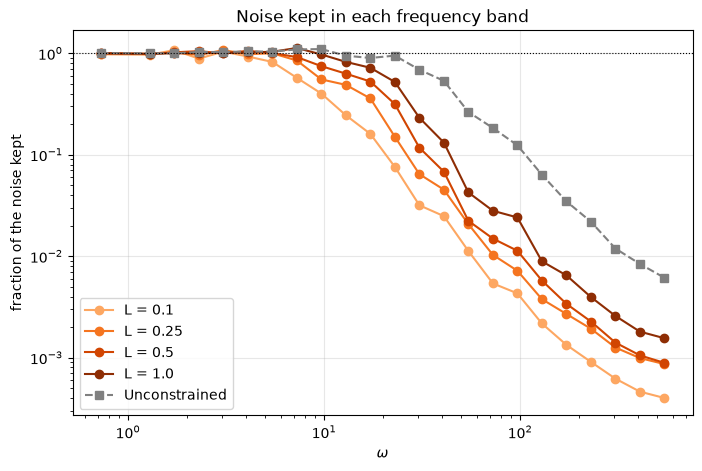

MSE to the clean Gaussian (lower = better denoising)
   noisy training data itself: 3.75e-03
   L = 0.1: 5.41e-05 ± 2.3e-06
   L = 0.25: 7.63e-05 ± 2.5e-06
   L = 0.5: 9.23e-05 ± 2.4e-06
   L = 1.0: 1.21e-04 ± 1.8e-06
   unconstrained: 2.05e-04 ± 5.0e-06


In [165]:
# Evaluation: which frequencies of the noise does each network keep?
# White noise has no individual waves, so instead of following single waves we divide the frequencies into bands.
# In each band we compare the noise that is left in the output (output - clean Gaussian) with the noise in the data:
#     fraction kept = sqrt( sum of (amplitude left)^2 in the band / sum of (noise amplitude)^2 in the band )
# This is the white-noise version of "the fraction of each wave that survives".
# Note: the error left in the output also contains any distortion of the Gaussian itself. That only matters at the lowest
# frequencies, where the Gaussian has its energy.

omega_white, amplitude_noise_white = fourier_spectrum(x_white, white_noise)

# Logarithmic bands from the lowest to the highest frequency on the grid
band_edges = np.logspace(np.log10(omega_white[1]), np.log10(omega_white[-1]), 25)

# Keep only the bands that contain at least one FFT frequency. At the lowest frequencies a logarithmic band can be
# narrower than the spacing between the FFT frequencies, and would then be empty.
band_lower = []
band_upper = []
for i in range(len(band_edges) - 1):
    in_band = (omega_white >= band_edges[i]) & (omega_white < band_edges[i + 1])
    if np.sum(in_band) > 0:
        band_lower.append(band_edges[i])
        band_upper.append(band_edges[i + 1])
band_lower = np.array(band_lower)
band_upper = np.array(band_upper)
band_centres = np.sqrt(band_lower * band_upper)   # middle of each band on a logarithmic axis


def fraction_kept_per_band(prediction):
    """Fraction of the noise amplitude that is left in the prediction, in each frequency band."""
    omega, amplitude_left = fourier_spectrum(x_white, prediction - gaussian_white)
    fractions = []
    for i in range(len(band_lower)):
        in_band = (omega >= band_lower[i]) & (omega < band_upper[i])
        fractions.append(np.sqrt(np.sum(amplitude_left[in_band] ** 2) / np.sum(amplitude_noise_white[in_band] ** 2)))
    return np.array(fractions)


# Plot: one line per network (mean over seeds)
plt.figure(figsize=(8, 5))
colors = plt.cm.Oranges(np.linspace(0.4, 0.95, len(L_VALUES)))
for L, color in zip(L_VALUES, colors):
    fractions = []
    for seed in SEEDS:
        fractions.append(fraction_kept_per_band(predictions_white[L][seed]))
    plt.plot(band_centres, np.mean(fractions, axis=0), 'o-', color=color, label=f'L = {L}')

fractions = []
for seed in SEEDS:
    fractions.append(fraction_kept_per_band(predictions_white_unconstrained[seed]))
plt.plot(band_centres, np.mean(fractions, axis=0), 's--', color='grey', label='Unconstrained')

plt.axhline(1, color='black', linestyle=':', linewidth=0.8)
plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$\omega$')
plt.ylabel('fraction of the noise kept')
plt.title('Noise kept in each frequency band')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Denoising: MSE against the CLEAN Gaussian. The noisy data itself has MSE = mean(noise^2)
print("MSE to the clean Gaussian (lower = better denoising)")
print(f"   noisy training data itself: {np.mean(white_noise ** 2):.2e}")
for L in L_VALUES:
    mse_clean = []
    for seed in SEEDS:
        mse_clean.append(np.mean((predictions_white[L][seed] - gaussian_white) ** 2))
    print(f"   L = {L}: {np.mean(mse_clean):.2e} ± {np.std(mse_clean):.1e}")
mse_clean = []
for seed in SEEDS:
    mse_clean.append(np.mean((predictions_white_unconstrained[seed] - gaussian_white) ** 2))
print(f"   unconstrained: {np.mean(mse_clean):.2e} ± {np.std(mse_clean):.1e}")

Network              noise removed    remaining error / noise
L = 0.1             100.0 ±  0.0 %           0.014 ± 0.001
L = 0.25             99.9 ±  0.0 %           0.020 ± 0.001
L = 0.5              99.9 ±  0.0 %           0.025 ± 0.001
L = 1.0              99.9 ±  0.0 %           0.032 ± 0.000
Unconstrained        99.7 ±  0.0 %           0.055 ± 0.001


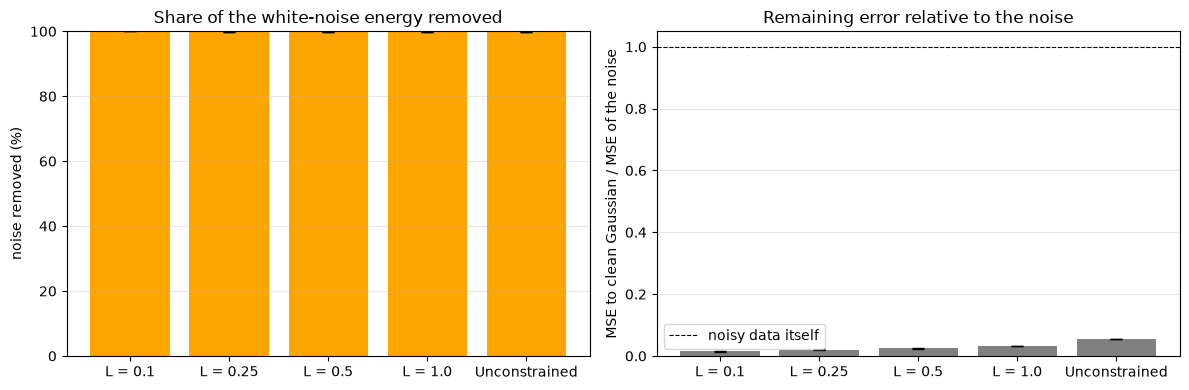

In [166]:
# How much of the white noise does each network remove?
# Two numbers per network (mean ± std over seeds), the white-noise versions of the ones in the sine-wave section:
#  1) Noise removed: how much of the actual noise pattern is gone from the output. We split the error of the output,
#     (output - clean Gaussian), into a part that is a copy of the noise and a rest:
#         output - clean Gaussian = copied * noise + rest,   copied = sum((output - clean) * noise) / sum(noise^2)
#     copied = 1 means the network reproduced the noise exactly, copied = 0 means none of it.
#     The noise energy that is kept is copied^2, so  noise removed = 1 - copied^2.
#  2) Remaining error relative to the noise: mean((output - clean Gaussian)^2) / mean(noise^2).
#     This counts everything that is still wrong. Below 1 means the output is closer to the clean Gaussian than the data was.

def white_noise_removed(prediction):
    """Share of the noise energy that the prediction did not copy."""
    copied = np.sum((prediction - gaussian_white) * white_noise) / np.sum(white_noise ** 2)
    return 1 - copied ** 2


def white_remaining_error(prediction):
    """Mean squared distance to the clean Gaussian, relative to the mean squared noise in the data."""
    return np.mean((prediction - gaussian_white) ** 2) / np.mean(white_noise ** 2)


# Collect the numbers for every network
names = []
removed_mean, removed_std = [], []
error_mean, error_std = [], []

for L in L_VALUES:
    removed = [white_noise_removed(predictions_white[L][seed]) for seed in SEEDS]
    error = [white_remaining_error(predictions_white[L][seed]) for seed in SEEDS]
    names.append(f'L = {L}')
    removed_mean.append(np.mean(removed)); removed_std.append(np.std(removed))
    error_mean.append(np.mean(error)); error_std.append(np.std(error))

removed = [white_noise_removed(predictions_white_unconstrained[seed]) for seed in SEEDS]
error = [white_remaining_error(predictions_white_unconstrained[seed]) for seed in SEEDS]
names.append('Unconstrained')
removed_mean.append(np.mean(removed)); removed_std.append(np.std(removed))
error_mean.append(np.mean(error)); error_std.append(np.std(error))

# Table
print(f"{'Network':15s} {'noise removed':>18s} {'remaining error / noise':>26s}")
for i in range(len(names)):
    print(f"{names[i]:15s} {100 * removed_mean[i]:9.1f} ± {100 * removed_std[i]:4.1f} %"
          f" {error_mean[i]:15.3f} ± {error_std[i]:.3f}")

# Bar plots of the two numbers
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

axs[0].bar(names, 100 * np.array(removed_mean), yerr=100 * np.array(removed_std), capsize=4, color='orange')
axs[0].set_ylabel('noise removed (%)')
axs[0].set_title('Share of the white-noise energy removed')
axs[0].set_ylim(0, 100)

axs[1].bar(names, error_mean, yerr=error_std, capsize=4, color='grey')
axs[1].axhline(1, color='black', linestyle='--', linewidth=0.8, label='noisy data itself')
axs[1].set_ylabel('MSE to clean Gaussian / MSE of the noise')
axs[1].set_title('Remaining error relative to the noise')
axs[1].legend()

for ax in axs:
    ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()